# Predict hurricane size with a neural network

Joshua Bare's network (first version: tag `first-version`, this file), fixed. The layers and the
training are unchanged; the code now lives in `hurricane/deep.py` so the app can use it too.

What was wrong in the first version, and what changed:

1. **One scaler for two jobs.** `scaler.fit_transform(x)` then `scaler.fit_transform(y)` refitted
   the same MinMaxScaler to the sizes, so the input scaling was gone and the saved network could
   not be given a real storm. Its predictions were in 0-1 units; a raw row gave -65.
   Now inputs and sizes each have their own scaler, fitted on training rows only.
2. **The row number was an input.** `num` runs in date order. The network now sees the six storm
   measures the forest uses: central pressure, max winds, radius of max winds, outer isobar,
   latitude, longitude.
3. **Rows with a missing value were dropped** (54 of 170, mostly unknown radius of max winds, and
   19 dates lost to NOAA's footnote marks). Missing values are now imputed and no date is lost.
4. **Scored on one random split of landfalls.** A storm that crosses several coasts has one row per
   landfall with the same size, so a random split tests the network on storms it trained on.
   Here whole storms are held out.

In [1]:
import os, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd
sys.path.insert(0, "..")
import matplotlib.pyplot as plt, seaborn as sns
from hurricane.data import load_landfalls, STORM_MEASURES
from hurricane.deep import SizeNetwork, build
from hurricane.model import evaluate, make_forest, storm_splits

df = load_landfalls("../Hurricane_dataset - Sheet1.csv")
print(len(df), "landfalls from", df.storm.nunique(), "storms")
df[STORM_MEASURES + ["Size_nm"]].describe().round(1)
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

170 landfalls from 137 storms


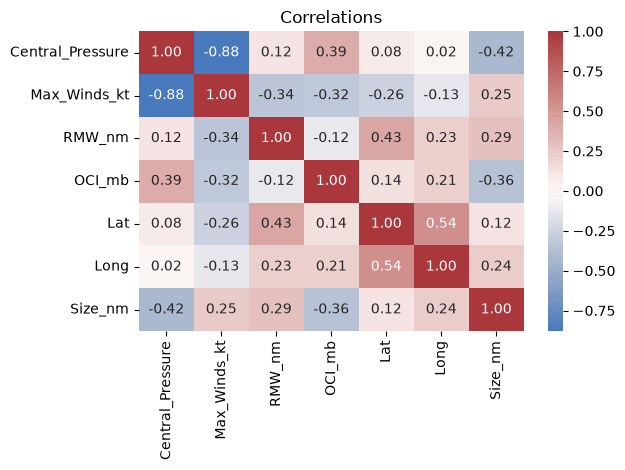

In [2]:
# Central pressure is the measure most related to size (negative: deeper storms are larger).
sns.heatmap(df[STORM_MEASURES + ["Size_nm"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlations"); plt.tight_layout(); plt.show()

In [3]:
build(len(STORM_MEASURES)).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,561 (10.00 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Ten splits that hold whole storms out, the network and the forest on the same splits.
splits = storm_splits(df, n_splits=10)
net = evaluate(df, lambda k: SizeNetwork(seed=k), STORM_MEASURES, splits)
forest = evaluate(df, make_forest, STORM_MEASURES, splits)
pd.DataFrame({
    "network MAE (nm)": net["mae"].round(1),
    "forest MAE (nm)": forest["mae"].round(1),
    "guess the mean (nm)": net["mean_guess_mae"].round(1),
}).describe().loc[["mean", "std", "min", "max"]].round(1)

,network MAE (nm),forest MAE (nm),guess the mean (nm)
mean,63.0,56.6,69.5
std,6.8,6.5,9.9
min,54.9,49.7,50.1
max,77.3,67.4,83.4


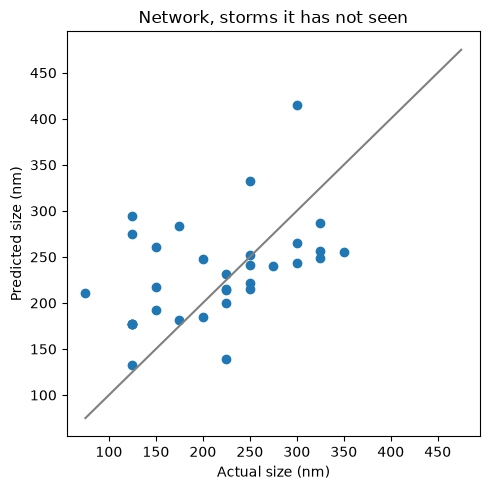

In [5]:
# One held-out split, in nautical miles.
train, test = splits[0]
X, y = df[STORM_MEASURES], df["Size_nm"].to_numpy()
m = SizeNetwork(seed=0).fit(X.iloc[train], y[train])
pred = m.predict(X.iloc[test])
plt.figure(figsize=(5, 5))
plt.scatter(y[test], pred)
plt.plot([75, 475], [75, 475], color="grey")
plt.xlabel("Actual size (nm)"); plt.ylabel("Predicted size (nm)")
plt.title("Network, storms it has not seen"); plt.tight_layout(); plt.show()

On storms it has not seen the network's size is off by about 63 nm on average, the forest's by
about 57 and always guessing the average by about 70 (`results/evaluation.md` has the full run).
With 170 landfalls the network has little to learn from; stopping its training early did not help
(64 nm on the same splits). The app offers it beside the forest and says how far off each one is.

The app's copy is trained on every landfall by `python scripts/train.py` and saved to
`Hurricane_model/size_network.keras` with its scalers.